# IND320 Assignment 4

## Introduction

This is a Jupyter Notebook for the fourth part of the IND320 - Data to Decision Project Work. This notebook includes:

* Links to Github repository and Streamlit app
* Description of AI Usage
* NOK/USD and NOK/EUR currency exchange rates from Norges Bank API, Open-Meteo weather data for NVE areas, SPC and LOF outlier detection, STL, a spectrogram, and locations saved for the app.

### Video and Links to Github and Streamlit

Github: https://github.com/MagnusFrantsen/IND320-MagnusFrantsen  
Streamlit: https://ind320-magnusfrantsen.streamlit.app/

The video is uploaded to the Github Repository as: "IND320_Project_Work_Part_4.mp4"

### Log Describing Compulsory Work

This section contains a log of the workflow with the Jupyter Notebook and Streamlit App:

I continued on the demo branch in the same Github Repository and Streamlit app, to make sure my changes did not affect the feedback for part 3.

First I inspected the Norges Bank API on "https://www.norges-bank.no/en/topics/statistics/open-data/guide-data-warehouse/" to figure out how to build up the request to make the API call.



### AI Usage

The AI model used during this assignment was Claude Opus 5.5 and Claude Fable 5.2 (the few days it was a part of the Pro-plan).

Generally, the AI model has suggested code, and most of the code in this assignment was copied from these suggestions and then adapted by me. I have tried to understand each part by asking follow-up questions about what the code does and why it is needed.

More specifically the AI model has been used for:

* Breaking down the task description into concrete steps for both the notebook and the Streamlit app
* Finding the correct layers in NVE Atlas and checking the downloaded shapefiles
* Clipping the areas to land and sampling 1000 random locations in each area
* Creating the Open-Meteo download function, and reducing the number of API calls by merging locations into ERA5 grid cells
* Creating the functions for the DCT filtering, SPC boundaries, LOF, STL and spectrogram, and the tests of these functions
* Explaining concepts such as the Discrete Cosine Transform, robust statistics and the use of st.stop()
* Designing the global area selector and how the weather data is loaded in the Streamlit app
* Debugging errors, and finding that the VASS areas in the data did not match the areas listed by the API
* Restructuring the Streamlit pages, the navigation and the home page, and providing documentation for st.tabs and st.navigation
* Writing a first draft of the work log and this section, which I reviewed and edited

I have personally reviewed, tested and adapted the generated code, and written most of the comments myself, to make sure I understand what the code is actually doing and to get the desired functionality.

# Tasks

## Downloading Euro and USD currency exchange rates

### Importing needed modules

In [10]:
import requests
import pandas as pd
import io

### Defining the base URL of the API

In [2]:
BASE_URL = "https://data.norges-bank.no/api/data/EXR/"

### Defining the download function

In [14]:
def get_currency_exchange_rates(currencies, start, end, freq="B"):
    """Fetching NOK exchange rates from NB as a pandas DataFrame

    currencies: list of ISO code, here ["USD", "EUR"]
    start, end: dates in the format "YYYY-MM-DD"
    freq: "B" (business daily), "M" (monthly) and "A" (annual)
    """

    key = f"{freq}.{'+'.join(currencies)}.NOK.SP"

    params = {
        "format": "csv",       # one observation per row
        "startPeriod": start,
        "endPeriod": end,
        "locale": "en",
    }

    response = requests.get(BASE_URL + key, params=params, timeout=30)

    response.raise_for_status()

    # Separating the csv-formatted files by semicolon
    exchange_rates = pd.read_csv(io.StringIO(response.text), sep=";")

    # Converting the time-column to datetime timestamps
    exchange_rates["TIME_PERIOD"] = pd.to_datetime(exchange_rates["TIME_PERIOD"])

    # Returning a pivot table from the exchange_rates DataFrame 
    return exchange_rates.pivot(index="TIME_PERIOD", columns = "BASE_CUR", values = "OBS_VALUE")

### Downloading the data

In [ ]:
# Verifying that the function is able to download the data from 2024-01-01 to 2026-11-13
exchange_rates = get_currency_exchange_rates(["USD", "EUR"], "2024-01-01", "2026-11-13")
# Printing the last 5 rows of the pivot
print(exchange_rates.tail())

BASE_CUR         EUR     USD
TIME_PERIOD                 
2026-11-09   10.5325  9.4099
2026-11-10   10.6155  9.4663
2026-11-11   10.6145  9.5394
2026-11-12   10.5630  9.5325
2026-11-13   10.5695  9.5634


## About Time Zone Differences

Below is a table used to summarize the Time Zone Convention used by the different APIs as default, also including the resolution of the data. 

| Source            | Resolution       | Time convention            |
|-------------------|------------------|----------------------------|
| Magasinstatistikk | Weekly           | Date only, Norwegian time  |
| ENTSO-E           | Hourly           | UTC                        |
| Open-Meteo        | Hourly           | GMT by default             |
| Norges Bank       | Business daily   | Date only                  |

Here is how the APIs are treated at this point in the assignments:

- **ENTSO-E:** requested, parsed and stored in UTC; Spark session time zone set to UTC.
- **Open-Meteo:** requested with `timezone="UTC"` and parsed as UTC.
- **Magasinstatistikk and Norges Bank:** date only, treated as Norwegian calendar dates; no conversion needed.
- **Grouping and plotting:** UTC timestamps are converted to `Europe/Oslo` before grouping by year and month.
- **Combining sources:** hourly data is converted to `Europe/Oslo` and aggregated to Monday–Sunday weeks to match the weekly reservoir data.

As I am going to make a forecasting model, I need one row per time step. Because the lowest resolution is weekly (Magasinstatistikk), I have to convert the other data to a weekly resolution, because that will be the highest resolution the model will be able to predict at, since the data spans several years, I think a weekly or even monthly resolution will be sufficient. And I will test both below.

## Converting to weekly resolution

### Function for weekly resolution

In [18]:
def to_nve_weeks(data, how="mean"):
    """Aggregate a time-indexed Series/DataFrame to NVE weeks
    
    Weeks run Monday-Sunday in Norwegian time and are labelled with the
    Sunday date, matching the Magasinstatistikk measurement.

    data: indexed by timestamps, either UTC-aware (ENTSO-E, Open-Meteo)
          or date-only (Norges Bank)
    how: aggregation per week, e.g. "mean", "sum" or "last"
    """

    # Checking if the data has a timezone, shifting it to Norwegian time if it does
    if data.index.tz is not None:
        data = data.tz_convert("Europe/Oslo")

    # One row per week, labelled with the Sunday that ends the week to match Magasinstatistikk
    weekly = data.resample("W-SUN").agg(how)

    # Dropping the time zone, so all sources get plain dates that can be joined
    weekly.index = weekly.index.tz_localize(None)
    return weekly

In [19]:
# Weekly mean exchange rate per currency
exchange_rates_weekly = to_nve_weeks(exchange_rates)
print(exchange_rates_weekly.tail())

BASE_CUR         EUR      USD
TIME_PERIOD                  
2026-10-18   10.6487  9.50360
2026-10-25   10.5093  9.37124
2026-11-01   10.3668  9.29372
2026-11-08   10.4111  9.28732
2026-11-15   10.5790  9.50230


Verifying that the weather data from Open-Meteo matches the Magasinstatistikk resolution after using to_nve_weaks on the store CSV-file:

In [20]:
# Hourly weather already stored in the repository (UTC timestamps)
weather = pd.read_csv("../data/NO3_2024_hourly.csv", parse_dates=["time"]).set_index("time")
weather_weekly = to_nve_weeks(weather)

# Reservoir dates from the API, limited to the same year as the weather file
URL_MAGASIN = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
magasin = pd.DataFrame(requests.get(URL_MAGASIN, timeout=15).json())
magasin["dato_Id"] = pd.to_datetime(magasin["dato_Id"])

# Check 1: reservoir dates should all be Sundays
print(magasin["dato_Id"].dt.day_name().value_counts())

# Check 2: weekly labels with no matching reservoir date (should be an empty list)
print(list(weather_weekly.index.difference(magasin["dato_Id"])))

# Check 3: hours per week (168, plus 167/169 at the clock changes and short edge weeks)
print(to_nve_weeks(weather["temperature_2m"], "count").value_counts())

dato_Id
Sunday    14958
Name: count, dtype: int64
[]
temperature_2m
168    49
167     2
169     1
49      1
Name: count, dtype: int64


In [21]:
# Weekly mean exchange rate per currency
exchange_rates_weekly = to_nve_weeks(exchange_rates)

# Check 1: weekly labels should all be Sundays
print(exchange_rates_weekly.index.day_name().value_counts())

# Check 2: weekly labels with no matching reservoir date
# (should only be the newest week(s), which NVE has not published yet)
print(list(exchange_rates_weekly.index.difference(magasin["dato_Id"])))

# Check 3: number of business days behind each weekly mean (normally 5)
print(to_nve_weeks(exchange_rates["EUR"], "count").value_counts())

TIME_PERIOD
Sunday    150
Name: count, dtype: int64
[Timestamp('2026-11-15 00:00:00')]
EUR
5    129
4     16
3      3
2      2
Name: count, dtype: int64


The missing Timestamp will not be matched by a reservoir value and can be disregarded going forward.

## Creating the Prediction for the Coming Months

In [27]:
from river import time_series, linear_model, optim, preprocessing

In [23]:
# River's online SARIMAX: learns one observation at a time
model = time_series.SNARIMAX(
    p=1, d=0, q=1,        # non-seasonal orders
    m=52,                 # season length: 52 weeks in a year
    sp=1, sd=0, sq=0,     # seasonal orders
)

Now using the 

In [24]:
# Prints the number of rows if the variables still exist in memory
print(len(magasin), len(exchange_rates))

14958 722


In [30]:
import sys

# Adding the project root (one level up) to the search path, so utils.py can be found
sys.path.append("..")

# Makes matplotlib draw figures inside the notebook
%matplotlib inline

from utils import filling_series

In [26]:
# Renaming the reservoir columns to the same English names as in the earlier assignments
magasin.columns = ['Date', 'area_type', 'area_nr', 'iso_year', 'iso_week',
                   'res_level', 'capacity_TWh', 'res_level_TWh',
                   'next_publish_date', 'prev_res_level', 'change_res_level']

# Weekly filling in percent for one region (EL 3 = price area NO3)
filling = filling_series(magasin, omr_type="EL", omr_nr=3)
print(filling.tail())

Date
2026-10-11    72.523980
2026-10-18    72.494050
2026-10-25    71.764696
2026-11-01    72.014890
2026-11-08    71.876454
Freq: 7D, Name: res_level, dtype: float64


In [28]:
# One row per week: the filling (target) plus the weekly exchange rates.
# join="inner" keeps only weeks that exist in both, so the unpublished week is dropped
weekly = pd.concat([filling.rename("filling"), exchange_rates_weekly], axis=1, join="inner")
print(weekly.tail())

              filling      EUR      USD
2026-10-11  72.523980  10.7360  9.57856
2026-10-18  72.494050  10.6487  9.50360
2026-10-25  71.764696  10.5093  9.37124
2026-11-01  72.014890  10.3668  9.29372
2026-11-08  71.876454  10.4111  9.28732


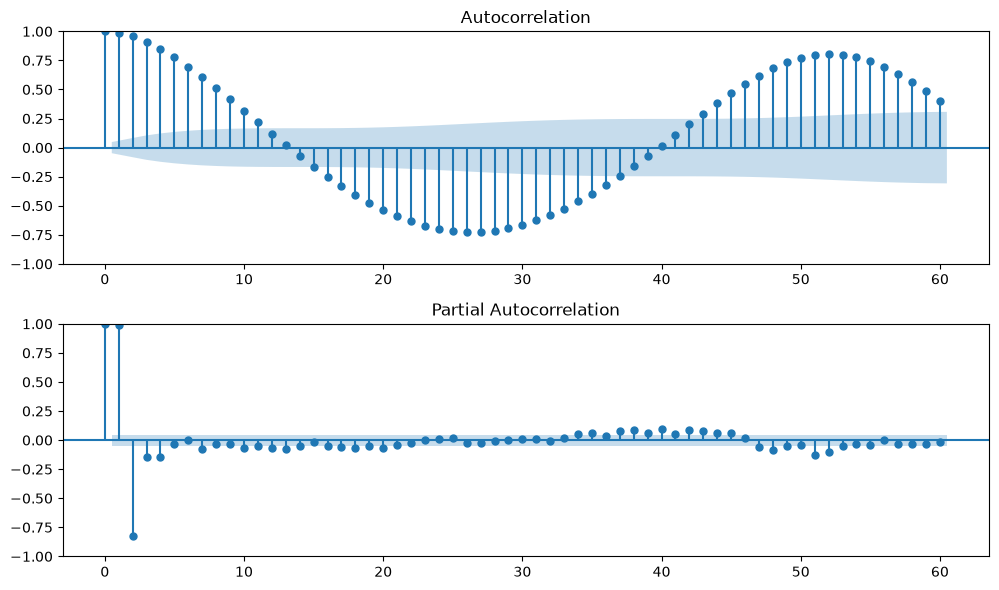

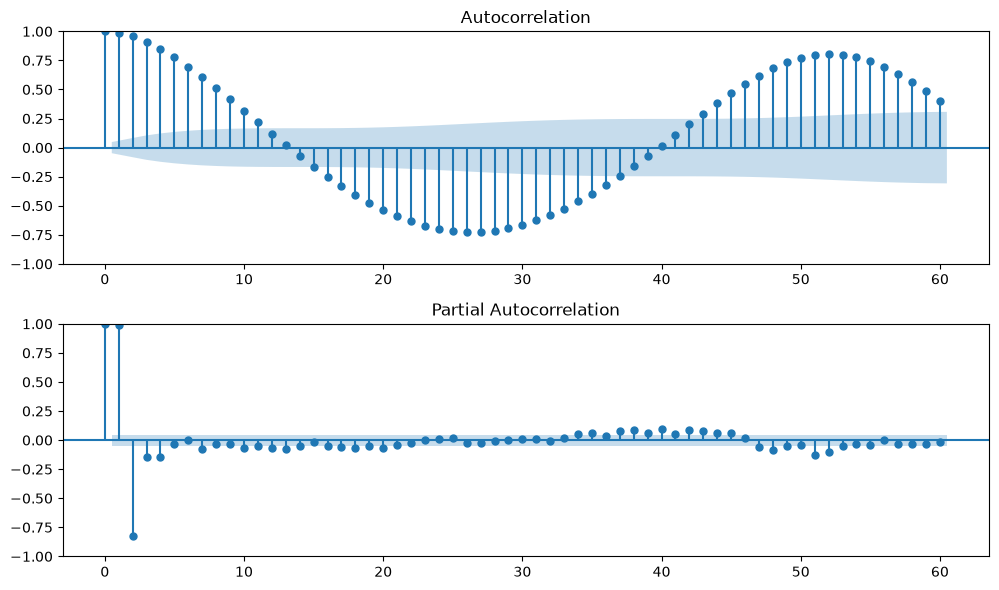

In [31]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Autocorrelation (top) and partial autocorrelation (bottom) of the weekly filling.
# 60 lags so the yearly lag at 52 weeks is visible
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
sm.graphics.tsa.plot_acf(filling, lags=60, ax=axes[0])
sm.graphics.tsa.plot_pacf(filling, lags=60, ax=axes[1])
plt.tight_layout()
plt.show()

In [ ]:
def forecast_filling(series, p=2, d=0, q=0, m=52, sp=1, sd=0, sq=0,
                     history=None, horizon=26, offset=0):
    """Forecast the filling and test it against the last `horizon` weeks.

    series: weekly filling in percent, indexed by date
    p, d, q: settings for the recent weeks
    m, sp, sd, sq: settings for the yearly pattern
    history: number of weeks to learn from (None = all available)
    horizon: number of weeks to forecast
    offset: number of weeks to step back before testing (0 = most recent)
    Returns the forecast and its mean absolute error.
    """

    # Stepping back in time: dropping the most recent `offset` weeks
    if offset > 0:
        series = series[:-offset]
    
    # Hiding the last `horizon` weeks from the model
    train, test = series[:-horizon], series[-horizon:]

    # Keeping only the most recent `history` weeks to learn from
    if history is not None:
        train = train[-history:] 

    model = time_series.SNARIMAX(
        p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq,
        regressor=(
            preprocessing.StandardScaler()
            | linear_model.LinearRegression(optimizer=optim.SGD(0.01))
        ),
    )

    # Learning one week at a time, oldest first
    for y in train:
        model.learn_one(y)

    # Forecasting the hidden weeks and measuring the error
    forecast = pd.Series(model.forecast(horizon=horizon), index=test.index)
    error = (forecast - test).abs().mean()
    return forecast, error

In [44]:
# Same settings, different amounts of history (in weeks)
forecast_1, error_1 = forecast_filling(filling, history=None)  # all available weeks
print(f"Error: {error_1:.2f} percentage points")

forecast_2, error_2 = forecast_filling(filling, history=104)
print(f"Error: {error_2:.2f} percentage points")  # last 2 years only

Error: 6.74 percentage points
Error: 4.40 percentage points


In [51]:
# Testing both history settings on four different half-years
for offset in [0, 52, 104, 156]:
    _, err_all = forecast_filling(filling, history=None, offset=offset)
    _, err_2y = forecast_filling(filling, history=104, offset=offset)
    print(f"{offset:>3} weeks ({offset/52:.0f} year(s)) back: all history {err_all:.2f}, two years {err_2y:.2f}")

  0 weeks (0 year(s)) back: all history 6.74, two years 4.40
 52 weeks (1 year(s)) back: all history 8.10, two years 1058.32
104 weeks (2 year(s)) back: all history 19.03, two years 33.60
156 weeks (3 year(s)) back: all history 11.68, two years 31.22


In [52]:
import time

def test_settings(series, settings, offsets=(0, 52, 104, 156)):
    """Test several settings on several periods and return one row per setting.

    series: weekly filling, as given to forecast_filling
    settings: list of dictionaries, each holding inputs for forecast_filling
    offsets: how many weeks to step back for each test period
    Returns a table sorted with the lowest average error first.
    """
    rows = []
    for setting in settings:
        start = time.perf_counter()

        # One error per test period for this setting
        errors = [forecast_filling(series, offset=o, **setting)[1] for o in offsets]

        # Storing the setting together with its average error, worst error and run time
        rows.append({**setting,
                     "mean_error": sum(errors) / len(errors),
                     "worst_error": max(errors),
                     "seconds": time.perf_counter() - start})

    return pd.DataFrame(rows).sort_values("mean_error").round(2)

In [57]:
# Each dictionary is one setting to test. Use the same keys in every one
settings = [
    {"p": 2, "sd": 0, "history": None},
    {"p": 2, "sd": 0, "history": 104},
    {"p": 2, "sd": 1, "history": None},
    {"p": 4, "sd": 0, "history": None},
    {"p": 4, "sd": 1, "history": None},
]

results = test_settings(filling, settings, offsets=(0, 26, 52, 78, 104, 130))
results.style.hide(axis="index").format(precision=2, na_rep="all")

p,sd,history,mean_error,worst_error,seconds
2,1,all,8.62,24.09,0.08
4,1,all,8.85,25.29,0.09
4,0,all,13.59,27.24,0.09
2,0,all,14.99,33.17,0.12
2,0,104.00,26211.28,155324.60,0.02


### Testing of history length and model parameters (have to personalize this cell)

Each setting was tested on six different half-year periods for NO3. For each
period, the last 26 weeks were hidden from the model, forecast, and compared
with the actual filling. The periods are half a year apart, so they alternate
between summer–autumn and winter–spring. The table shows the mean absolute
error over the six periods, the error in the worst period, and the run time.

Findings:

- **Seasonal differencing (`sd=1`) gave the largest improvement.** The mean
  error fell from 14.99 to 8.62 percentage points, and the worst period from
  33.17 to 24.09.
- **More recent weeks (`p=4`) did not help once `sd=1` was used.** It reduced
  the error without seasonal differencing (13.59 against 14.99), but combined
  with `sd=1` the result was about the same (8.85 against 8.62). I therefore
  keep the simpler `p=2`.
- **Two years of history made the model unstable.** With only the last 104
  weeks, the forecast ran away to impossible values in several periods, so
  all available history is used.
- **Run time is not a limitation.** Each setting, which includes six training
  runs, took about 0.1 seconds at weekly resolution.

The best setting so far is `p=2`, `sd=1` with all available history. Its worst
period is still 24 percentage points off, which shows that some half-years,
especially winter and spring, are much harder to forecast than others.